<a href="https://colab.research.google.com/github/Rixdorfer-Kindl/protein-design-pipline-colab/blob/main/%E9%AA%A8%E6%9E%B6%E9%AA%8C%E8%AF%81.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#@title 🛠️ 安装依赖 { display-mode: "form" }
#@markdown 只需要 Biopython，其余（pandas、numpy、scipy、matplotlib）Colab 已自带。

!pip install -q biopython

import Bio, scipy, pandas, numpy, matplotlib
print("✅ 环境就绪 | Biopython", Bio.__version__, "| scipy", scipy.__version__)

✅ 环境就绪 | Biopython 1.88 | scipy 1.16.3


Structure exists: '/content/pdb6aru.ent' 

📁 /content/drive/MyDrive/RFdiffusion/group4: 找到 8 个骨架文件, hotspot(1IVO) = [467, 468, 471, 472]


,file,target_range,ref_covered,min_dist,n_atom_contacts,n_binder_int_res,n_target_int_res,hs467,hs468,hs471,hs472,hs_min_dist,hs_touched,hs_total
0,group4_0.pdb,78-214,345-481,5.24,0,0,0,6.23 (→200),5.58 (→201),5.68 (→204),6.63 (→205),5.58,0,4
1,group4_1.pdb,72-208,345-481,6.27,0,0,0,7.16 (→194),6.27 (→195),7.8 (→198),8.52 (→199),6.27,0,4
2,group4_2.pdb,68-204,345-481,6.07,0,0,0,6.59 (→190),6.11 (→191),9.45 (→194),10.74 (→195),6.11,0,4
3,group4_3.pdb,62-198,345-481,6.20,0,0,0,7.21 (→184),6.2 (→185),6.45 (→188),7.75 (→189),6.20,0,4
4,group4_4.pdb,72-208,345-481,7.17,0,0,0,9.33 (→194),7.63 (→195),8.49 (→198),9.1 (→199),7.63,0,4
5,group4_5.pdb,64-200,345-481,4.16,20,6,6,5.76 (→186),4.16 (→187),4.94 (→190),5.1 (→191),4.16,2,4
6,group4_6.pdb,61-197,345-481,7.47,0,0,0,7.53 (→183),7.47 (→184),11.75 (→187),12.91 (→188),7.47,0,4
7,group4_7.pdb,74-210,345-481,6.60,0,0,0,8.05 (→196),6.6 (→197),6.95 (→200),6.61 (→201),6.60,0,4


/tmp/ipykernel_2473/1679821756.py:128: UserWarning: Glyph 26368 (\N{CJK UNIFIED IDEOGRAPH-6700}) missing from font(s) DejaVu Sans.
  plt.suptitle(""); plt.tight_layout(); plt.show()
/tmp/ipykernel_2473/1679821756.py:128: UserWarning: Glyph 36817 (\N{CJK UNIFIED IDEOGRAPH-8FD1}) missing from font(s) DejaVu Sans.
  plt.suptitle(""); plt.tight_layout(); plt.show()
/tmp/ipykernel_2473/1679821756.py:128: UserWarning: Glyph 36317 (\N{CJK UNIFIED IDEOGRAPH-8DDD}) missing from font(s) DejaVu Sans.
  plt.suptitle(""); plt.tight_layout(); plt.show()
/tmp/ipykernel_2473/1679821756.py:128: UserWarning: Glyph 31163 (\N{CJK UNIFIED IDEOGRAPH-79BB}) missing from font(s) DejaVu Sans.
  plt.suptitle(""); plt.tight_layout(); plt.show()
/tmp/ipykernel_2473/1679821756.py:128: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.suptitle(""); plt.tight_layout(); plt.show()
/tmp/ipykernel_2473/1679821756.py:128: UserWarning: Glyph 23376 (\N{CJK UNIFIED IDEOGRAPH-

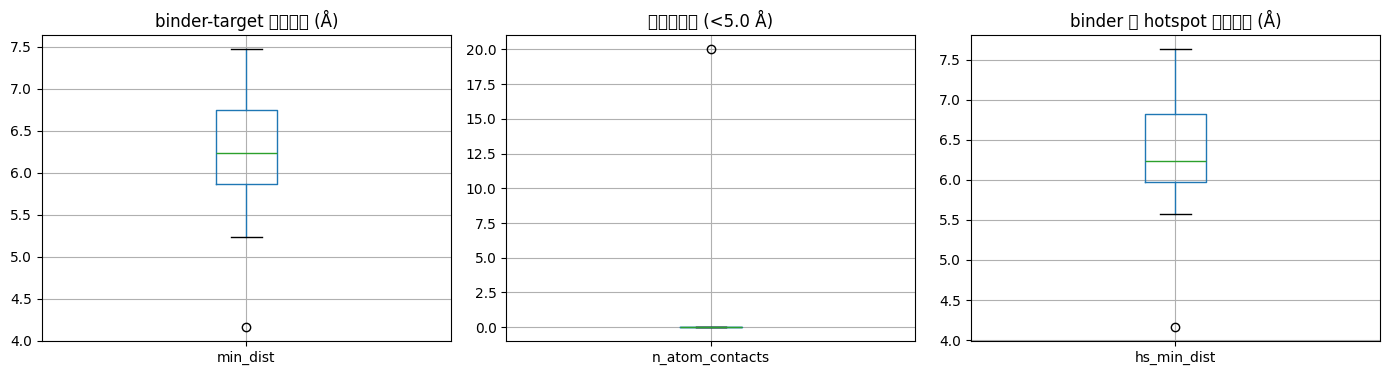

💾 已保存: /content/drive/MyDrive/RFdiffusion/group4/backbone_interface_summary.csv


In [3]:
#@title 📏 骨架界面分析 (逐骨架 hotspot 映射 + 距离) { display-mode: "form" }
import os, glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from Bio.PDB import PDBParser, PDBList
from Bio.Align import PairwiseAligner
from Bio.Data.IUPACData import protein_letters_3to1
from google.colab import drive

if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

#@markdown ### 📁 路径
base_dir = "/content/drive/MyDrive/RFdiffusion/group4" #@param {type:"string"}
binder_chain = "A" #@param {type:"string"}
target_chain = "B" #@param {type:"string"}
contact_cutoff = 5.0 #@param {type:"number"}

#@markdown ### 🎯 Hotspot 设置
ref_pdb_id = "6ARU" #@param {type:"string"}
ref_chain = "A" #@param {type:"string"}
#@markdown 请在下方输入 hotspot 编号，用英文逗号分隔，例如: `392, 397` 或 `431, 400, 376`
hotspots_input = "467,468,471,472" #@param {type:"string"}

# 解析用户手动输入的 hotspots
hotspots = [int(x.strip()) for x in hotspots_input.split(",") if x.strip().isdigit()]

parser = PDBParser(QUIET=True)

def residue_list(chain):
    out = []
    for r in chain:
        if r.id[0] != " ":
            continue
        aa = protein_letters_3to1.get(r.get_resname().capitalize())
        if aa:
            out.append((r.id[1], aa, r))
    return out

# --- 参考结构 ---
ref_path = PDBList().retrieve_pdb_file(ref_pdb_id, pdir="/content", file_format="pdb")
ref = residue_list(parser.get_structure("ref", ref_path)[0][ref_chain])
ref_seq = "".join(a for _, a, _ in ref)
ref_aa = {n: a for n, a, _ in ref}

aligner = PairwiseAligner()
aligner.mode = "local"
aligner.match_score, aligner.mismatch_score = 2, -1
aligner.open_gap_score, aligner.extend_gap_score = -5, -0.5

def map_numbers(sub):
    """返回 {1IVO编号: (骨架编号, 氨基酸是否一致)}"""
    sub_seq = "".join(a for _, a, _ in sub)
    aln = aligner.align(ref_seq, sub_seq)[0]
    m = {}
    for (r0, r1), (s0, s1) in zip(*aln.aligned):
        for k in range(r1 - r0):
            rn, ra, _ = ref[r0 + k]
            sn, sa, _ = sub[s0 + k]
            m[rn] = (sn, ra == sa)
    return m

def heavy(chain_res):
    return [a for r in chain_res for a in r if a.element != "H"]

rows = []
# 直接遍历 base_dir 下的所有 PDB 文件
files = sorted(glob.glob(os.path.join(base_dir, "*.pdb")))
print(f"\n📁 {base_dir}: 找到 {len(files)} 个骨架文件, hotspot(1IVO) = {hotspots}")

for f in files:
    name = os.path.basename(f)
    try:
        model = parser.get_structure("s", f)[0]
        if binder_chain not in model or target_chain not in model:
            print(f"  ⚠️ {name}: 链 ID 不匹配"); continue
        tgt = residue_list(model[target_chain])
        mp = map_numbers(tgt)
        cov = (min(mp), max(mp)) if mp else (None, None)

        b_atoms = heavy(model[binder_chain])
        t_atoms = heavy(model[target_chain])
        bc = np.array([a.coord for a in b_atoms])
        tc = np.array([a.coord for a in t_atoms])
        D = cdist(bc, tc)
        hit = D < contact_cutoff
        b_int = {b_atoms[i].get_parent().id[1] for i in np.where(hit.any(1))[0]}
        t_int = {t_atoms[j].get_parent().id[1] for j in np.where(hit.any(0))[0]}

        row = {"file": name,
               "target_range": f"{tgt[0][0]}-{tgt[-1][0]}",
               "ref_covered": f"{cov[0]}-{cov[1]}",
               "min_dist": round(float(D.min()), 2),
               "n_atom_contacts": int(hit.sum()),
               "n_binder_int_res": len(b_int),
               "n_target_int_res": len(t_int)}

        hs_d = []
        for h in hotspots:
            if h not in mp:
                row[f"hs{h}"] = "outside"; hs_d.append(np.nan); continue
            sn, same = mp[h]
            idx = [j for j, a in enumerate(t_atoms) if a.get_parent().id[1] == sn]
            d = float(D[:, idx].min())
            hs_d.append(d)
            row[f"hs{h}"] = f"{round(d,2)} (→{sn}{'' if same else ' ⚠aa不符'})"
        row["hs_min_dist"] = round(float(np.nanmin(hs_d)), 2) if not np.all(np.isnan(hs_d)) else np.nan
        row["hs_touched"] = int(np.sum(np.array(hs_d) < contact_cutoff))
        row["hs_total"] = len(hotspots)
        rows.append(row)
    except Exception as e:
        print(f"  ❌ {name}: {e}")

if rows:
    df_bb = pd.DataFrame(rows)
    out_csv = os.path.join(base_dir, "backbone_interface_summary.csv")
    df_bb.to_csv(out_csv, index=False)

    pd.set_option("display.width", 250, "display.max_columns", 30)
    display(df_bb)

    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    df_bb.boxplot(column="min_dist", ax=ax[0]); ax[0].set_title("binder-target 最近距离 (Å)")
    df_bb.boxplot(column="n_atom_contacts", ax=ax[1]); ax[1].set_title(f"原子接触数 (<{contact_cutoff} Å)")
    df_bb.boxplot(column="hs_min_dist", ax=ax[2]); ax[2].set_title("binder 到 hotspot 最近距离 (Å)")
    plt.suptitle(""); plt.tight_layout(); plt.show()
    print(f"💾 已保存: {out_csv}")
else:
    print("❌ 未在该文件夹下找到有效的骨架或链匹配！")